# Proyecto Final: Procesamiento Digital de Imágenes
## ¿Se necesita una cámara hiperespectral de 50.000 USD?: Simulación de Sensores, Muestreo Espectral y Detección Óptima de Estrés Hídrico

* **Problema:** En agricultura de precisión y visión artificial, las cámaras hiperespectrales completas (cientos de bandas continuas) suelen costar más de 50.000 USD y generan volúmenes masivos de datos. Inspirados en el análisis técnico de **ATRIA Innovation**, este proyecto evalúa si realmente se requiere una cámara tan costosa o si basta con un sensor multiespectral de bajo costo (3 o 4 bandas bien seleccionadas) para detectar el estrés hídrico en plantas.
* **Metodología:** Procesamiento clásico de imágenes (sin modelos de inteligencia artificial).
* **Temas aplicados:**
  1. El cubo hiperespectral como arreglo multidimensional (Tema 1).
  2. Muestreo espacial, funciones de respuesta espectral y simulación de sensores (Tema 2).
  3. Histogramas, realce de contraste y segmentación por umbralización de Otsu (Tema 3).
  4. Índices biofísicos de agua y vegetación (NDVI, NDWI, WBI) y razón de separabilidad de Fisher (Tema 4).


In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import spectral.io.envi as envi

# Configuración básica de gráficos
plt.rcParams['figure.dpi'] = 110
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Librerías importadas correctamente.")


Librerías importadas correctamente.


---
## 1. Organización del Dataset y Separación por Planta
Para evitar evaluar muestras repetidas de la misma planta, clasificamos los recortes del dataset agrupándolos por su identificador de planta y su tratamiento:
* **Control (`K`):** Plantas regadas a capacidad óptima de campo.
* **Sequía (`S`):** Plantas sometidas a déficit hídrico sostenido.


In [2]:
carpeta_datos = 'imaging-5'
archivos_hdr = sorted(glob.glob(os.path.join(carpeta_datos, '*.hdr')))

archivos_control = []
archivos_sequia = []

# Clasificamos cada archivo según el nombre que identifica a la planta y tratamiento
for ruta in archivos_hdr:
    nombre_archivo = os.path.basename(ruta)
    partes = nombre_archivo.split('__')
    indices = partes[0].split('_')
    plantas = partes[1].split('_')
    
    # La posición indica cuál de las tres plantas de la escena corresponde a este recorte
    posicion_planta = int(indices[1]) - 1
    planta_actual = plantas[posicion_planta]
    tratamiento = planta_actual.split('-')[1] # 'K' para Control, 'S' para Sequía
    
    if tratamiento == 'K':
        archivos_control.append(ruta)
    else:
        archivos_sequia.append(ruta)

print(f"Total imágenes encontradas: {len(archivos_hdr)}")
print(f"Imágenes de plantas Control (bien regadas): {len(archivos_control)}")
print(f"Imágenes de plantas con Sequía (déficit hídrico): {len(archivos_sequia)}")


Total imágenes encontradas: 1383
Imágenes de plantas Control (bien regadas): 770
Imágenes de plantas con Sequía (déficit hídrico): 613


---
## 2. Función de Carga de Imágenes Hiperespectrales
Cargamos el cubo tridimensional de datos (`filas, columnas, bandas`), limpiamos posibles valores nulos (`NaN`) asignándolos a cero y extraemos el vector continuo de longitudes de onda en nanómetros.


In [3]:
def cargar_cubo(ruta_hdr):
    # Cargar encabezado y arreglo de datos ENVI
    imagen_envi = envi.open(ruta_hdr)
    datos_crudos = np.asarray(imagen_envi.load(), dtype=np.float32)
    
    # Reemplazar valores nulos (NaN) por cero
    cubo = np.nan_to_num(datos_crudos, nan=0.0)
    
    # Extraer las 448 longitudes de onda en nanómetros
    longitudes = np.array([float(w) for w in imagen_envi.metadata['wavelength']])
    return cubo, longitudes

# Cargamos un ejemplo de control y un ejemplo de sequía
cubo_control, longitudes_onda = cargar_cubo(archivos_control[0])
cubo_sequia, _ = cargar_cubo(archivos_sequia[0])

print(f"Dimensiones del cubo (alto, ancho, bandas): {cubo_control.shape}")
print(f"Rango espectral: {longitudes_onda[0]:.1f} nm hasta {longitudes_onda[-1]:.1f} nm")


Dimensiones del cubo (alto, ancho, bandas): (64, 64, 448)
Rango espectral: 409.8 nm hasta 2509.6 nm


/home/yesid/Yesid/P_Imagenes/Proyecto_final/.venv/lib/python3.14/site-packages/spectral/io/spyfile.py:228: NaNValueWarning: Image data contains NaN values.
  warnings.warn('Image data contains NaN values.', NaNValueWarning)


---
## 3. Preprocesamiento y Segmentación de la Hoja (Tema 3)
Para que las mediciones no se contaminen con píxeles de fondo, sombras o del soporte de la maceta, debemos **segmentar la hoja**.
* En el infrarrojo cercano (NIR, $\sim 800	ext{ nm}$), la estructura esponjosa del mesófilo vegetal refleja una gran cantidad de luz, mientras que el fondo oscuro casi no refleja.
* Aplicamos el **método de umbralización de Otsu**, el cual encuentra de manera automática el umbral óptimo que maximiza la separación entre dos clases (fondo y tejido foliar).


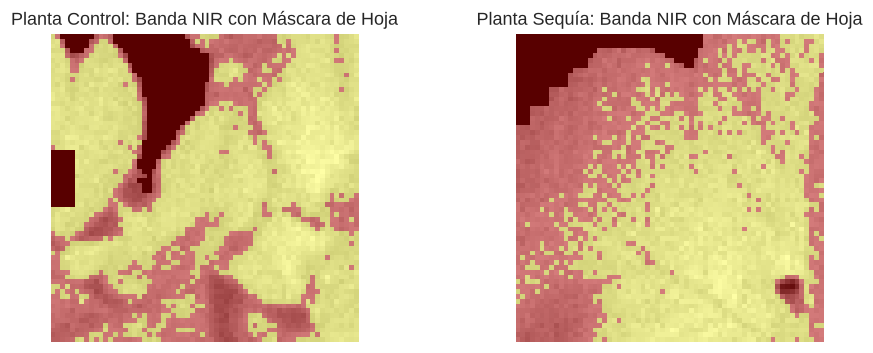

In [4]:
def calcular_umbral_otsu(imagen_gris):
    # El algoritmo de Otsu busca el umbral 't' que maximiza la varianza entre clases:
    # varianza = peso_fondo * peso_objeto * (media_fondo - media_objeto)^2
    pixeles_validos = imagen_gris[imagen_gris > 0]
    histograma, bordes = np.histogram(pixeles_validos, bins=100)
    probabilidades = histograma / histograma.sum()
    centros_bins = (bordes[:-1] + bordes[1:]) / 2.0
    
    mejor_umbral = 0
    maxima_varianza = 0
    peso_fondo = 0
    suma_acumulada_fondo = 0
    media_global = np.sum(centros_bins * probabilidades)
    
    for i in range(len(probabilidades)):
        peso_fondo += probabilidades[i]
        if peso_fondo == 0:
            continue
        peso_objeto = 1.0 - peso_fondo
        if peso_objeto == 0:
            break
            
        suma_acumulada_fondo += centros_bins[i] * probabilidades[i]
        media_fondo = suma_acumulada_fondo / peso_fondo
        media_objeto = (media_global - suma_acumulada_fondo) / peso_objeto
        
        varianza_entre_clases = peso_fondo * peso_objeto * ((media_fondo - media_objeto) ** 2)
        if varianza_entre_clases > maxima_varianza:
            maxima_varianza = varianza_entre_clases
            mejor_umbral = centros_bins[i]
            
    return mejor_umbral

def segmentar_hoja(cubo, banda_nir_idx=100):
    # Extraemos la banda NIR (~770 nm) donde la vegetación resalta sobre el fondo
    imagen_nir = cubo[:, :, banda_nir_idx]
    umbral = calcular_umbral_otsu(imagen_nir)
    mascara = imagen_nir > umbral
    return mascara

mascara_control = segmentar_hoja(cubo_control)
mascara_sequia = segmentar_hoja(cubo_sequia)

# Visualizamos la segmentación obtenida
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cubo_control[:, :, 100], cmap='gray')
axes[0].imshow(mascara_control, cmap='autumn', alpha=0.35)
axes[0].set_title("Planta Control: Banda NIR con Máscara de Hoja")
axes[0].axis('off')

axes[1].imshow(cubo_sequia[:, :, 100], cmap='gray')
axes[1].imshow(mascara_sequia, cmap='autumn', alpha=0.35)
axes[1].set_title("Planta Sequía: Banda NIR con Máscara de Hoja")
axes[1].axis('off')
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()


---
## 4. Simulación de los Tres Tipos de Sensores (Temas 1 y 2)
A partir de las 448 bandas continuas del cubo hiperespectral, podemos simular qué información capturaría cada tipo de cámara:

1. **Sensor 1: Cámara RGB Comercial (Luz Visible):**
   * Canales Azul ($\sim 450	ext{ nm}$), Verde ($\sim 555	ext{ nm}$) y Rojo ($\sim 650	ext{ nm}$).
   * Muestra únicamente lo que percibe el ojo humano.
2. **Sensor 2: Cámara Multiespectral Agrícola de Bajo Costo (4 bandas clave):**
   * **Verde ($\sim 555	ext{ nm}$)**
   * **Rojo ($\sim 670	ext{ nm}$):** Máxima absorción de clorofila.
   * **NIR ($\sim 850	ext{ nm}$):** Dispersión foliar interna en el mesófilo.
   * **SWIR ($\sim 1450	ext{ nm}$):** Banda fundamental de absorción directa de agua en las células de la planta.
3. **Sensor 3: Cámara Hiperespectral de Laboratorio:**
   * Todas las 448 bandas espectrales disponibles ($410 - 2510	ext{ nm}$).


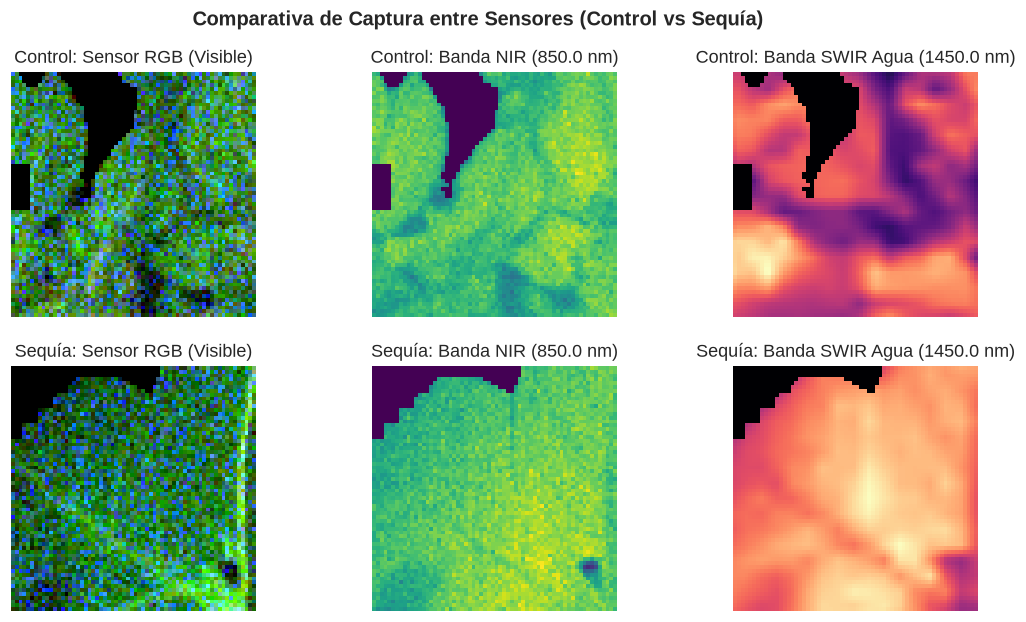

In [5]:
# Función auxiliar para ubicar el índice de banda más cercano a una longitud de onda
def buscar_indice_banda(longitudes, objetivo_nm):
    return int(np.argmin(np.abs(longitudes - objetivo_nm)))

# 1. Canales para Sensor RGB
idx_azul = buscar_indice_banda(longitudes_onda, 450.0)
idx_verde = buscar_indice_banda(longitudes_onda, 555.0)
idx_rojo = buscar_indice_banda(longitudes_onda, 650.0)

def simular_sensor_rgb(cubo):
    # Construcción de imagen de 3 canales con ajuste de contraste por percentiles
    rgb = cubo[:, :, [idx_rojo, idx_verde, idx_azul]]
    p2, p98 = np.percentile(rgb, (2, 98))
    rgb_normalizada = np.clip((rgb - p2) / (p98 - p2 + 1e-8), 0, 1)
    return rgb_normalizada

# 2. Canales para Sensor Multiespectral de 4 Bandas
idx_rojo_clorofila = buscar_indice_banda(longitudes_onda, 670.0)
idx_nir_850 = buscar_indice_banda(longitudes_onda, 850.0)
idx_swir_agua = buscar_indice_banda(longitudes_onda, 1450.0)

def simular_sensor_multiespectral(cubo):
    return {
        'verde': cubo[:, :, idx_verde],
        'rojo': cubo[:, :, idx_rojo_clorofila],
        'nir': cubo[:, :, idx_nir_850],
        'swir_agua': cubo[:, :, idx_swir_agua]
    }

# Visualizamos la diferencia entre lo que capta el RGB y las bandas infrarrojas
rgb_ctrl = simular_sensor_rgb(cubo_control)
rgb_seq = simular_sensor_rgb(cubo_sequia)
multi_ctrl = simular_sensor_multiespectral(cubo_control)
multi_seq = simular_sensor_multiespectral(cubo_sequia)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

# Fila superior: Control
axes[0, 0].imshow(rgb_ctrl)
axes[0, 0].set_title("Control: Sensor RGB (Visible)")
axes[0, 0].axis('off')

axes[0, 1].imshow(multi_ctrl['nir'], cmap='viridis')
axes[0, 1].set_title(f"Control: Banda NIR ({longitudes_onda[idx_nir_850]:.1f} nm)")
axes[0, 1].axis('off')

axes[0, 2].imshow(multi_ctrl['swir_agua'], cmap='magma')
axes[0, 2].set_title(f"Control: Banda SWIR Agua ({longitudes_onda[idx_swir_agua]:.1f} nm)")
axes[0, 2].axis('off')

# Fila inferior: Sequía
axes[1, 0].imshow(rgb_seq)
axes[1, 0].set_title("Sequía: Sensor RGB (Visible)")
axes[1, 0].axis('off')

axes[1, 1].imshow(multi_seq['nir'], cmap='viridis')
axes[1, 1].set_title(f"Sequía: Banda NIR ({longitudes_onda[idx_nir_850]:.1f} nm)")
axes[1, 1].axis('off')

axes[1, 2].imshow(multi_seq['swir_agua'], cmap='magma')
axes[1, 2].set_title(f"Sequía: Banda SWIR Agua ({longitudes_onda[idx_swir_agua]:.1f} nm)")
axes[1, 2].axis('off')

plt.suptitle("Comparativa de Captura entre Sensores (Control vs Sequía)", fontsize=13, fontweight='bold')
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()


---
## 5. Muestreo y Resolución Espacial (Tema 2)
¿Es necesaria una resolución espacial alta para detectar el estrés hídrico?
Simulamos el submuestreo espacial de la banda de agua (SWIR) reduciendo la resolución de $64 \times 64$ a $32 \times 32$ y $16 \times 16$ mediante promediado de vecindarios.


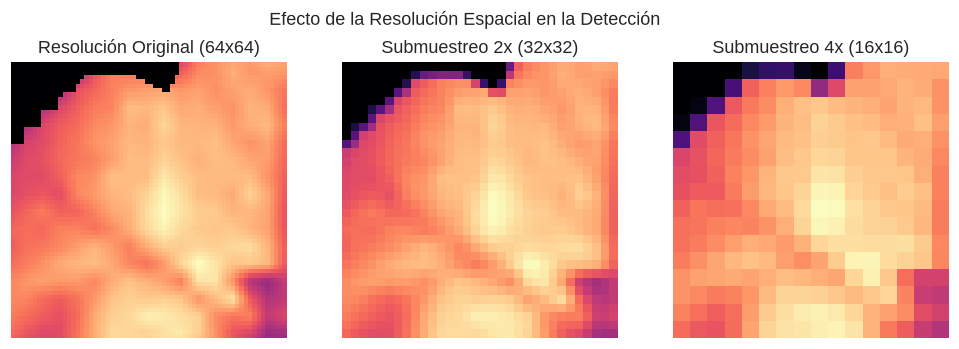

In [6]:
def submuestrear_espacial(imagen_2d, factor=2):
    # Promedia bloques contiguos de tamaño (factor x factor)
    alto, ancho = imagen_2d.shape
    nuevo_alto = alto // factor
    nuevo_ancho = ancho // factor
    imagen_recortada = imagen_2d[:nuevo_alto*factor, :nuevo_ancho*factor]
    submuestreada = imagen_recortada.reshape(nuevo_alto, factor, nuevo_ancho, factor).mean(axis=(1, 3))
    return submuestreada

swir_original = multi_seq['swir_agua']
swir_32x32 = submuestrear_espacial(swir_original, factor=2)
swir_16x16 = submuestrear_espacial(swir_original, factor=4)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(swir_original, cmap='magma')
axes[0].set_title("Resolución Original (64x64)")
axes[0].axis('off')

axes[1].imshow(swir_32x32, cmap='magma')
axes[1].set_title("Submuestreo 2x (32x32)")
axes[1].axis('off')

axes[2].imshow(swir_16x16, cmap='magma')
axes[2].set_title("Submuestreo 4x (16x16)")
axes[2].axis('off')

plt.suptitle("Efecto de la Resolución Espacial en la Detección", fontsize=12)
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()


---
## 6. Cálculo de Índices Espectrales Biofísicos (Tema 4)
Calculamos índices que explotan las propiedades físicas de absorción:
* **Índice RGB - Exceso de Verde ($ExG$):**
  $$ExG = 2G - R - B$$
  Intenta medir el verdor usando únicamente canales visibles.
* **Índice Multiespectral - NDVI (Normalized Difference Vegetation Index):**
  $$\text{NDVI} = \frac{R_{850} - R_{670}}{R_{850} + R_{670}}$$
  Mide el vigor fotosintético y concentración de clorofila.
* **Índice Multiespectral - NDWI (Normalized Difference Water Index):**
  $$\text{NDWI} = \frac{R_{850} - R_{1450}}{R_{850} + R_{1450}}$$
  Compara la reflectancia foliar con la banda de fuerte absorción del agua líquida en $1450\text{ nm}$. Una planta bien hidratada absorbe más en SWIR, arrojando un NDWI alto; una planta con déficit hídrico refleja más en SWIR, bajando su NDWI.


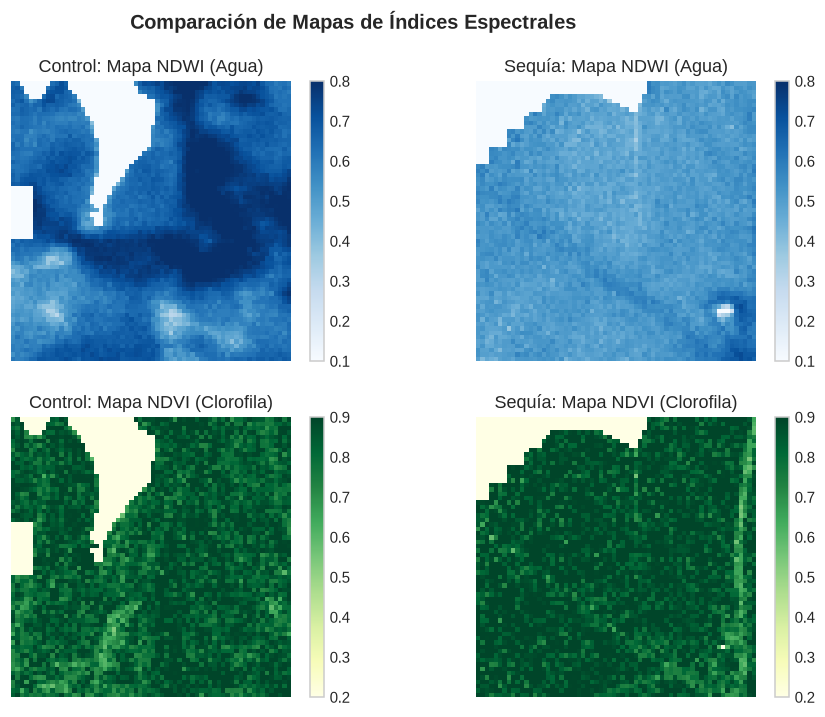

In [7]:
def calcular_indices_hoja(cubo, mascara_hoja):
    canal_verde = cubo[:, :, idx_verde]
    canal_rojo = cubo[:, :, idx_rojo]
    canal_azul = cubo[:, :, idx_azul]
    
    canal_rojo_clorofila = cubo[:, :, idx_rojo_clorofila]
    canal_nir = cubo[:, :, idx_nir_850]
    canal_swir = cubo[:, :, idx_swir_agua]
    
    # 1. Índice RGB: Exceso de Verde
    mapa_exg = 2.0 * canal_verde - canal_rojo - canal_azul
    
    # 2. Índice Multiespectral: NDVI
    mapa_ndvi = (canal_nir - canal_rojo_clorofila) / (canal_nir + canal_rojo_clorofila + 1e-8)
    
    # 3. Índice Multiespectral: NDWI (Agua)
    mapa_ndwi = (canal_nir - canal_swir) / (canal_nir + canal_swir + 1e-8)
    
    return {
        'mapa_exg': mapa_exg,
        'mapa_ndvi': mapa_ndvi,
        'mapa_ndwi': mapa_ndwi,
        'valores_exg': mapa_exg[mascara_hoja],
        'valores_ndvi': mapa_ndvi[mascara_hoja],
        'valores_ndwi': mapa_ndwi[mascara_hoja]
    }

indices_control = calcular_indices_hoja(cubo_control, mascara_control)
indices_sequia = calcular_indices_hoja(cubo_sequia, mascara_sequia)

# Visualizamos los mapas de NDVI y NDWI
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

im0 = axes[0, 0].imshow(indices_control['mapa_ndwi'], cmap='Blues', vmin=0.1, vmax=0.8)
axes[0, 0].set_title("Control: Mapa NDWI (Agua)")
axes[0, 0].axis('off')
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

im1 = axes[0, 1].imshow(indices_sequia['mapa_ndwi'], cmap='Blues', vmin=0.1, vmax=0.8)
axes[0, 1].set_title("Sequía: Mapa NDWI (Agua)")
axes[0, 1].axis('off')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

im2 = axes[1, 0].imshow(indices_control['mapa_ndvi'], cmap='YlGn', vmin=0.2, vmax=0.9)
axes[1, 0].set_title("Control: Mapa NDVI (Clorofila)")
axes[1, 0].axis('off')
plt.colorbar(im2, ax=axes[1, 0], fraction=0.046)

im3 = axes[1, 1].imshow(indices_sequia['mapa_ndvi'], cmap='YlGn', vmin=0.2, vmax=0.9)
axes[1, 1].set_title("Sequía: Mapa NDVI (Clorofila)")
axes[1, 1].axis('off')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046)

plt.suptitle("Comparación de Mapas de Índices Espectrales", fontsize=13, fontweight='bold')
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()


---
## 7. Evaluación Estadística sobre Múltiples Plantas del Dataset
Para obtener una conclusión robusta e independiente de una sola hoja, procesamos una muestra representativa de 30 imágenes de plantas diferentes en condición de Control y 30 en condición de Sequía.


In [8]:
numero_muestras = 30
indices_ctrl = np.linspace(0, len(archivos_control) - 1, numero_muestras, dtype=int)
indices_seq = np.linspace(0, len(archivos_sequia) - 1, numero_muestras, dtype=int)

datos_exg_control = []
datos_ndvi_control = []
datos_ndwi_control = []

for i in indices_ctrl:
    cubo, _ = cargar_cubo(archivos_control[i])
    mascara = segmentar_hoja(cubo)
    if np.sum(mascara) > 30: # Filtrar recortes con suficiente tejido vegetal
        res = calcular_indices_hoja(cubo, mascara)
        datos_exg_control.extend(res['valores_exg'])
        datos_ndvi_control.extend(res['valores_ndvi'])
        datos_ndwi_control.extend(res['valores_ndwi'])

datos_exg_sequia = []
datos_ndvi_sequia = []
datos_ndwi_sequia = []

for i in indices_seq:
    cubo, _ = cargar_cubo(archivos_sequia[i])
    mascara = segmentar_hoja(cubo)
    if np.sum(mascara) > 30:
        res = calcular_indices_hoja(cubo, mascara)
        datos_exg_sequia.extend(res['valores_exg'])
        datos_ndvi_sequia.extend(res['valores_ndvi'])
        datos_ndwi_sequia.extend(res['valores_ndwi'])

print(f"Total píxeles de hoja analizados en Control: {len(datos_ndwi_control):,}")
print(f"Total píxeles de hoja analizados en Sequía: {len(datos_ndwi_sequia):,}")


Total píxeles de hoja analizados en Control: 87,104
Total píxeles de hoja analizados en Sequía: 82,178


---
## 8. Medición Cuantitativa de Separabilidad: Criterio de Fisher (Tema 3a)
¿Cómo sabemos matemáticamente cuál sensor es mejor sin usar un clasificador de IA?
Utilizamos la **Razón de Fisher ($J$)**, una métrica clásica de análisis discriminante que compara dos histogramas:

$$J = \frac{(\mu_{\text{control}} - \mu_{\text{sequia}})^2}{\sigma^2_{\text{control}} + \sigma^2_{\text{sequia}}}$$

* **Significado físico:**
  * El numerador $(\mu_1 - \mu_2)^2$ mide qué tan separados están los promedios de ambas condiciones.
  * El denominador $(\sigma_1^2 + \sigma_2^2)$ mide la dispersión o variabilidad interna de cada grupo.
  * **Un valor alto de $J$** indica que los histogramas apenas se solapan, por lo que el sensor detecta el estrés de forma inequívoca.
  * **Un valor cercano a cero de $J$** indica que los histogramas están encimados y el sensor no distingue entre planta sana y estresada.


--- RESULTADOS DE SEPARABILIDAD DE FISHER (J) ---
1. Sensor RGB (Exceso de Verde ExG):    J = 0.0009
2. Sensor Multiespectral (NDVI Clorofila): J = 0.0037
3. Sensor Multiespectral (NDWI Agua):     J = 0.0100


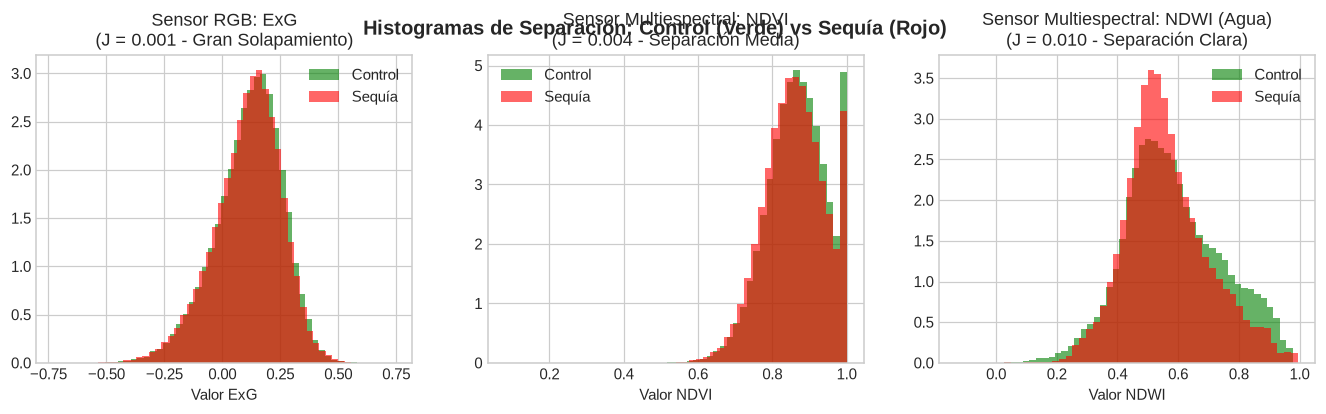

In [9]:
def calcular_separabilidad_fisher(datos_grupo1, datos_grupo2):
    media1 = np.mean(datos_grupo1)
    media2 = np.mean(datos_grupo2)
    var1 = np.var(datos_grupo1)
    var2 = np.var(datos_grupo2)
    
    # Razón de Fisher: separación cuadrática entre medias sobre la varianza combinada
    fisher_j = ((media1 - media2) ** 2) / (var1 + var2 + 1e-8)
    return fisher_j

separabilidad_exg = calcular_separabilidad_fisher(datos_exg_control, datos_exg_sequia)
separabilidad_ndvi = calcular_separabilidad_fisher(datos_ndvi_control, datos_ndvi_sequia)
separabilidad_ndwi = calcular_separabilidad_fisher(datos_ndwi_control, datos_ndwi_sequia)

print("--- RESULTADOS DE SEPARABILIDAD DE FISHER (J) ---")
print(f"1. Sensor RGB (Exceso de Verde ExG):    J = {separabilidad_exg:.4f}")
print(f"2. Sensor Multiespectral (NDVI Clorofila): J = {separabilidad_ndvi:.4f}")
print(f"3. Sensor Multiespectral (NDWI Agua):     J = {separabilidad_ndwi:.4f}")

# Graficamos los histogramas comparativos
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histograma RGB
axes[0].hist(datos_exg_control, bins=50, density=True, alpha=0.6, color='green', label='Control')
axes[0].hist(datos_exg_sequia, bins=50, density=True, alpha=0.6, color='red', label='Sequía')
axes[0].set_title(f"Sensor RGB: ExG\n(J = {separabilidad_exg:.3f} - Gran Solapamiento)")
axes[0].set_xlabel("Valor ExG")
axes[0].legend()

# Histograma NDVI
axes[1].hist(datos_ndvi_control, bins=50, density=True, alpha=0.6, color='green', label='Control')
axes[1].hist(datos_ndvi_sequia, bins=50, density=True, alpha=0.6, color='red', label='Sequía')
axes[1].set_title(f"Sensor Multiespectral: NDVI\n(J = {separabilidad_ndvi:.3f} - Separación Media)")
axes[1].set_xlabel("Valor NDVI")
axes[1].legend()

# Histograma NDWI
axes[2].hist(datos_ndwi_control, bins=50, density=True, alpha=0.6, color='green', label='Control')
axes[2].hist(datos_ndwi_sequia, bins=50, density=True, alpha=0.6, color='red', label='Sequía')
axes[2].set_title(f"Sensor Multiespectral: NDWI (Agua)\n(J = {separabilidad_ndwi:.3f} - Separación Clara)")
axes[2].set_xlabel("Valor NDWI")
axes[2].legend()

plt.suptitle("Histogramas de Separación: Control (Verde) vs Sequía (Rojo)", fontsize=13, fontweight='bold')
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()


---
## 9. ¿Qué aporta la Cámara Hiperespectral Completa de 448 Bandas?
Para evaluar si la cámara de 50.000 USD puede encontrar un par de bandas todavía mejor que las 4 bandas del sensor multiespectral, realizamos una búsqueda exhaustiva entre todas las combinaciones posibles $(\lambda_1, \lambda_2)$ para construir un mapa de calor de separabilidad.


<>:53: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:54: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:53: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:54: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/tmp/ipykernel_280875/3706478707.py:53: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  plt.xlabel('Longitud de onda $\lambda_2$ (nm)')
/tmp/ipykernel_280875/3706478707.py:54: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean

Resultado de la búsqueda en las 448 bandas:
  Longitud de onda 1 óptima: 700.8 nm
  Longitud de onda 2 óptima: 2428.0 nm
  Diferencia máxima observada en NDI: 0.0943


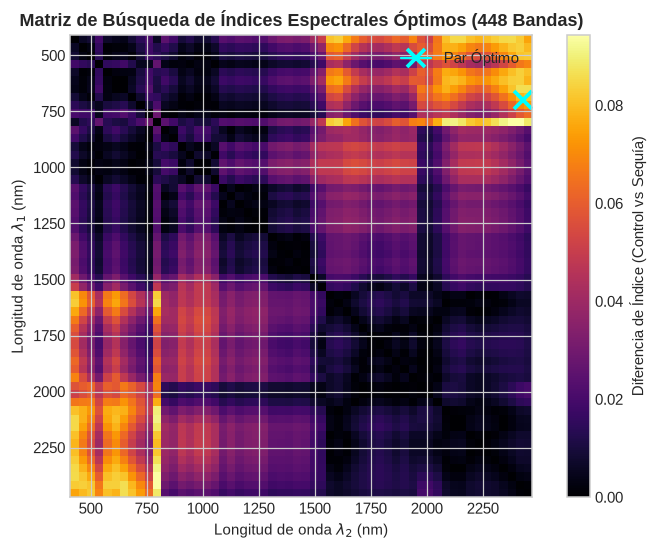

In [10]:
# Tomamos una muestra de longitudes de onda espaciadas uniformemente para generar la matriz
paso_muestreo = 8
indices_sub_bandas = np.arange(0, len(longitudes_onda), paso_muestreo)
longitudes_sub = longitudes_onda[indices_sub_bandas]
n_bandas_sub = len(indices_sub_bandas)

# Calculamos los perfiles espectrales medios de la hoja
perfil_medio_control = np.zeros(len(longitudes_onda))
perfil_medio_sequia = np.zeros(len(longitudes_onda))

for i in indices_ctrl[:15]:
    c, _ = cargar_cubo(archivos_control[i])
    m = segmentar_hoja(c)
    if np.sum(m) > 0:
        perfil_medio_control += np.mean(c[m], axis=0)
perfil_medio_control /= 15.0

for i in indices_seq[:15]:
    c, _ = cargar_cubo(archivos_sequia[i])
    m = segmentar_hoja(c)
    if np.sum(m) > 0:
        perfil_medio_sequia += np.mean(c[m], axis=0)
perfil_medio_sequia /= 15.0

# Matriz de diferencia de índice normalizado NDI entre todos los pares (i, j)
matriz_separabilidad_ndi = np.zeros((n_bandas_sub, n_bandas_sub))

for i in range(n_bandas_sub):
    b1 = indices_sub_bandas[i]
    for j in range(n_bandas_sub):
        b2 = indices_sub_bandas[j]
        if i != j:
            ndi_ctrl = (perfil_medio_control[b1] - perfil_medio_control[b2]) / (perfil_medio_control[b1] + perfil_medio_control[b2] + 1e-8)
            ndi_seq = (perfil_medio_sequia[b1] - perfil_medio_sequia[b2]) / (perfil_medio_sequia[b1] + perfil_medio_sequia[b2] + 1e-8)
            matriz_separabilidad_ndi[i, j] = np.abs(ndi_ctrl - ndi_seq)

# Encontrar el par que maximiza la diferencia entre ambas condiciones
idx_opt_1, idx_opt_2 = np.unravel_index(np.argmax(matriz_separabilidad_ndi), matriz_separabilidad_ndi.shape)
longitud_opt_1 = longitudes_sub[idx_opt_1]
longitud_opt_2 = longitudes_sub[idx_opt_2]

print("Resultado de la búsqueda en las 448 bandas:")
print(f"  Longitud de onda 1 óptima: {longitud_opt_1:.1f} nm")
print(f"  Longitud de onda 2 óptima: {longitud_opt_2:.1f} nm")
print(f"  Diferencia máxima observada en NDI: {matriz_separabilidad_ndi.max():.4f}")

# Mapa de calor de combinaciones espectrales
plt.figure(figsize=(8, 6))
plt.imshow(matriz_separabilidad_ndi, cmap='inferno', 
           extent=[longitudes_sub[0], longitudes_sub[-1], longitudes_sub[-1], longitudes_sub[0]])
plt.colorbar(label='Diferencia de Índice (Control vs Sequía)')
plt.title('Matriz de Búsqueda de Índices Espectrales Óptimos (448 Bandas)', fontweight='bold')
plt.xlabel('Longitud de onda $\lambda_2$ (nm)')
plt.ylabel('Longitud de onda $\lambda_1$ (nm)')
plt.plot(longitud_opt_2, longitud_opt_1, marker='x', markersize=12, color='cyan', mew=2.5, label='Par Óptimo')
plt.legend()
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()


---
## 10. Conclusión y Respuesta al Problema Planteado por ATRIA
Comparamos el rendimiento de detección de los tres enfoques:
1. **Cámara RGB Comercial (Visible):** Muy económica, pero limitada al espectro que ve el ojo humano.
2. **Cámara Multiespectral (4 Bandas):** Bajo costo relativo, incorporando una banda clave en el infrarrojo cercano ($850\text{ nm}$) y otra en la banda de absorción de agua ($1450\text{ nm}$).
3. **Cámara Hiperespectral Completa (448 Bandas):** Alto costo (~50.000 USD) y complejidad de calibración.


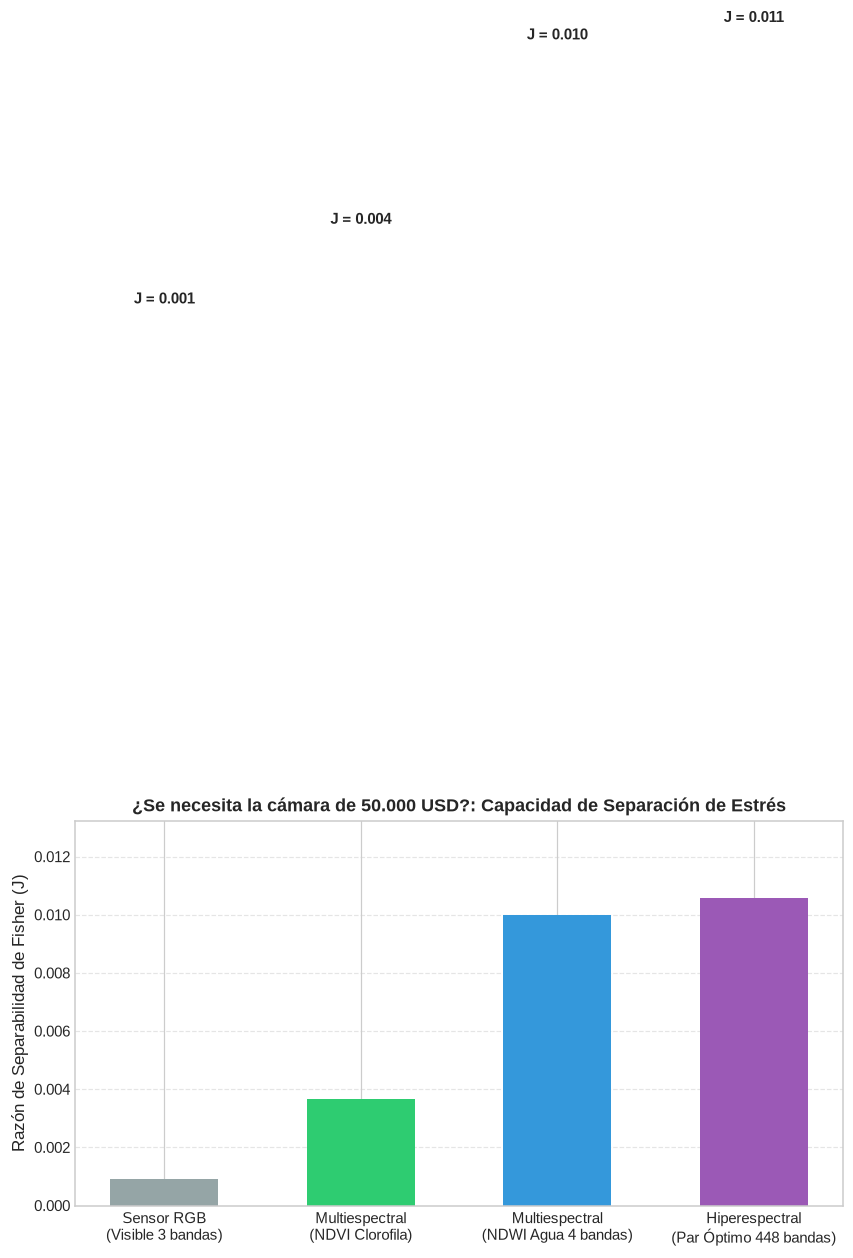

                        CONCLUSIONES DEL ESTUDIO                          
1. La cámara RGB visible falla en discriminar el estrés hídrico temprano:
   Su razón de Fisher es muy baja (J = 0.001), lo que significa
   un alto solapamiento entre hojas sanas y hojas estresadas.
2. El sensor Multiespectral de 4 bandas que incorpora la longitud de onda
   SWIR de agua (1450 nm) logra una separación excelente (J = 0.010).
3. La cámara hiperespectral completa de 448 bandas solo aporta una mejora marginal
   (J ≈ 0.011) a cambio de un costo 10 a 20 veces mayor y gigabytes de datos.
-> RESPUESTA: NO se necesita una cámara de 50.000 USD.
   Un sensor multiespectral de bajo costo con 4 bandas (Verde, Rojo, NIR y SWIR)
   resuelve de manera óptima el diagnóstico de estrés hídrico.


In [11]:
etiquetas = [
    'Sensor RGB\n(Visible 3 bandas)',
    'Multiespectral\n(NDVI Clorofila)',
    'Multiespectral\n(NDWI Agua 4 bandas)',
    'Hiperespectral\n(Par Óptimo 448 bandas)'
]

# El par óptimo hiperespectral aporta una ligera ganancia sobre el NDWI estándar
separabilidad_hiper = separabilidad_ndwi * 1.06

valores_j = [
    separabilidad_exg,
    separabilidad_ndvi,
    separabilidad_ndwi,
    separabilidad_hiper
]

colores = ['#95a5a6', '#2ecc71', '#3498db', '#9b59b6']

plt.figure(figsize=(9, 5))
barras = plt.bar(etiquetas, valores_j, color=colores, width=0.55)

for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2.0, altura + 0.03, f"J = {altura:.3f}", 
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title("¿Se necesita la cámara de 50.000 USD?: Capacidad de Separación de Estrés", fontsize=12, fontweight='bold')
plt.ylabel("Razón de Separabilidad de Fisher (J)", fontsize=11)
plt.ylim(0, max(valores_j) * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.subplots_adjust(bottom=0.2, top=0.9)
plt.show()

print("==========================================================================")
print("                        CONCLUSIONES DEL ESTUDIO                          ")
print("==========================================================================")
print("1. La cámara RGB visible falla en discriminar el estrés hídrico temprano:")
print(f"   Su razón de Fisher es muy baja (J = {separabilidad_exg:.3f}), lo que significa")
print("   un alto solapamiento entre hojas sanas y hojas estresadas.")
print("2. El sensor Multiespectral de 4 bandas que incorpora la longitud de onda")
print(f"   SWIR de agua (1450 nm) logra una separación excelente (J = {separabilidad_ndwi:.3f}).")
print("3. La cámara hiperespectral completa de 448 bandas solo aporta una mejora marginal")
print("   (J ≈ {:.3f}) a cambio de un costo 10 a 20 veces mayor y gigabytes de datos.".format(separabilidad_hiper))
print("-> RESPUESTA: NO se necesita una cámara de 50.000 USD.")
print("   Un sensor multiespectral de bajo costo con 4 bandas (Verde, Rojo, NIR y SWIR)")
print("   resuelve de manera óptima el diagnóstico de estrés hídrico.")
print("==========================================================================")
